# Phase 3: Autoencoder Latent Space Analysis

This notebook empirically determines the optimal latent dimension for the Autoencoder, trains the final model using a split-head composite loss, and visualizes the structured latent manifold to ensure biological plausibility for Phase 4 counterfactual search.

In [22]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import joblib
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
import umap
from kneed import KneeLocator

from src.data_pipeline import load_and_preprocess_data
from src.autoencoder import train_autoencoder

# Set global seeds
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)


In [23]:
# Load preprocessed, imputed, and scaled data
train_df, test_df, imm_feats, dir_feats, act_feats = load_and_preprocess_data(filepath="../data/frmgham2.csv", random_seed=RANDOM_SEED)

feature_cols = imm_feats + dir_feats + act_feats
print(f"Total features: {len(feature_cols)}")

# Uncensored 80/20 train/val split specifically for the Autoencoder
X_train, X_val, y_train_risk, y_val_risk = train_test_split(
    train_df[feature_cols].values, 
    train_df['ANYCHD'].values, # Extracted just for coloring plots later
    test_size=0.2, 
    random_state=RANDOM_SEED,
    stratify=train_df['ANYCHD'].values
)

print(f"AE Train shape: {X_train.shape}")
print(f"AE Val shape: {X_val.shape}")


Loading data from ../data/frmgham2.csv...

Missingness before imputation (%):
TIMECHD       0.000000
BPMEDS        1.250000
GLUCOSE       9.150943
ANYCHD        0.000000
HEARTRTE      0.023585
PREVHYP       0.000000
BMI           0.448113
PREVAP        0.000000
CIGPDAY       0.683962
TOTCHOL       1.179245
educ          2.476415
DIABETES      0.000000
PREVCHD       0.000000
SEX           0.000000
time_years    0.000000
CURSMOKE      0.000000
RANDID        0.000000
PREVMI        0.000000
AGE           0.000000
PREVSTRK      0.000000
SYSBP         0.000000
DIABP         0.000000
dtype: float64

--- Imputation Impact (Train Set) ---
AGE: mean shift=0.00%, var shift=0.00%
TOTCHOL: mean shift=0.01%, var shift=1.14%
SYSBP: mean shift=0.00%, var shift=0.00%
DIABP: mean shift=0.00%, var shift=0.00%
CIGPDAY: mean shift=0.65%, var shift=0.28%
BMI: mean shift=0.01%, var shift=0.47%
HEARTRTE: mean shift=0.00%, var shift=0.03%
GLUCOSE: mean shift=0.41%, var shift=9.11%
SEX: mean shift=0.00%, var sh

## 1. Empirical Latent Dimension Sweep
Rather than picking a latent dimension by convention, we train autoencoders at `dim = [2, 3, 4, 6, 8, 12, 16]` and plot the validation loss. We seek the smallest latent dimension that preserves reconstruction fidelity while avoiding a near-lossless identity mapping. A smaller space is mathematically constrained, which heavily benefits the Phase 4 counterfactual optimization by narrowing the search space.

*Selection Rule*: We use the **kneedle algorithm** (`kneed` library) to rigorously identify the point of maximum curvature (the "elbow" or "knee") on the convex, decreasing loss curve. This avoids arbitrary step-size heuristics and ensures we pick the point where diminishing returns objectively begin. Note that `patience=30` is used to ensure smaller dimensions fully converge.


In [24]:
latent_dims = [2, 3, 4, 6, 8, 12, 16]
sweep_results = []
trained_models = {}

print("Sweeping latent dimensions...")
for dim in latent_dims:
    # Increased patience to 30 to ensure smaller dimensions converge fully
    model, metrics = train_autoencoder(X_train, X_val, feature_cols, latent_dim=dim, epochs=150, patience=30)
    metrics['dim'] = dim
    sweep_results.append(metrics)
    trained_models[dim] = model
    print(f"Dim {dim} -> Total Loss: {metrics['Total Loss']:.4f} | Cont MSE: {metrics['Cont MSE']:.4f} | Bin Acc: {metrics['Bin Acc']:.2%} | Cat Acc: {metrics['Cat Acc']:.2%}")

sweep_df = pd.DataFrame(sweep_results)

# Selection Logic: Kneedle Algorithm
kl = KneeLocator(sweep_df['dim'], sweep_df['Total Loss'], curve='convex', direction='decreasing')
best_dim = int(kl.knee) if kl.knee is not None else 8

print(f"\nSelected Latent Dimension (Kneedle Algorithm): {best_dim}")

# Save the final chosen model
best_model = trained_models[best_dim]
os.makedirs('../models', exist_ok=True)
torch.save(best_model.state_dict(), '../models/autoencoder.pth')
joblib.dump({'latent_dim': best_dim, 'feature_cols': feature_cols}, '../models/ae_config.joblib')


Sweeping latent dimensions...
Dim 2 -> Total Loss: 0.6691 | Cont MSE: 0.5294 | Bin Acc: 94.81% | Cat Acc: 99.85%
Dim 3 -> Total Loss: 0.5706 | Cont MSE: 0.4499 | Bin Acc: 94.73% | Cat Acc: 100.00%
Dim 4 -> Total Loss: 0.3643 | Cont MSE: 0.2740 | Bin Acc: 96.61% | Cat Acc: 100.00%
Dim 6 -> Total Loss: 0.2071 | Cont MSE: 0.1433 | Bin Acc: 97.61% | Cat Acc: 100.00%
Dim 8 -> Total Loss: 0.1005 | Cont MSE: 0.0467 | Bin Acc: 98.36% | Cat Acc: 100.00%
Dim 12 -> Total Loss: 0.0128 | Cont MSE: 0.0049 | Bin Acc: 99.84% | Cat Acc: 100.00%
Dim 16 -> Total Loss: 0.0034 | Cont MSE: 0.0016 | Bin Acc: 99.98% | Cat Acc: 100.00%

Selected Latent Dimension (Kneedle Algorithm): 8


['../models/ae_config.joblib']

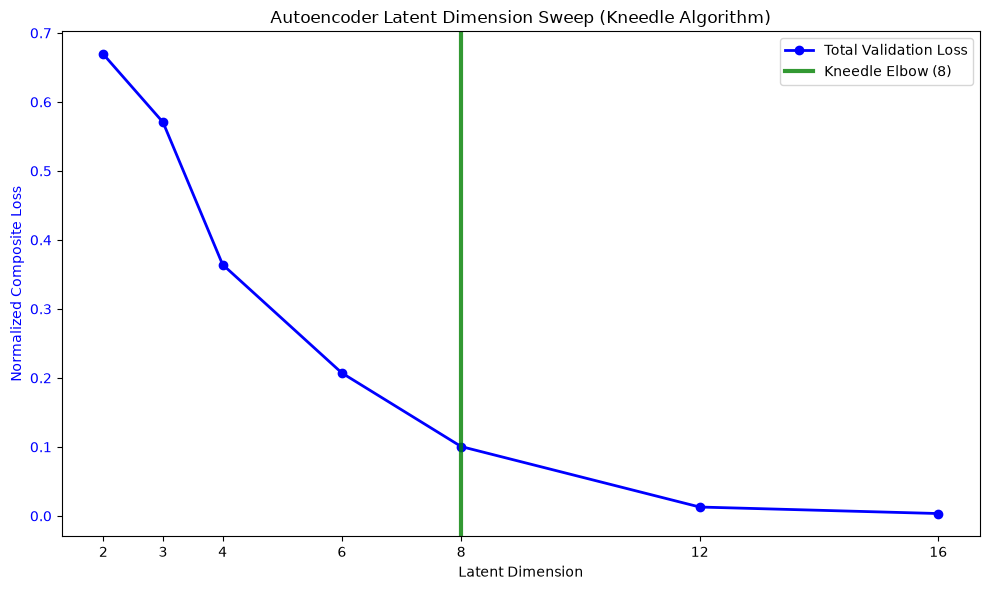

,Total Loss,Cont MSE,Bin BCE,Cat CE,Bin Acc,Cat Acc
dim,,,,,,
2,0.669062,0.529381,0.129353,0.010328,0.948126,0.998527
3,0.570559,0.449900,0.119001,0.001658,0.947308,1.000000
4,0.364268,0.273989,0.088786,0.001492,0.966127,1.000000
6,0.207111,0.143258,0.062064,0.001789,0.976109,1.000000
8,0.100508,0.046725,0.052451,0.001332,0.983636,1.000000
12,0.012849,0.004897,0.007679,0.000273,0.998364,1.000000
16,0.003416,0.001592,0.001655,0.000169,0.999836,1.000000


In [25]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(sweep_df['dim'], sweep_df['Total Loss'], marker='o', linewidth=2, color='blue', label='Total Validation Loss')
ax1.set_xlabel('Latent Dimension')
ax1.set_ylabel('Normalized Composite Loss', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xticks(latent_dims)

if kl.knee:
    plt.axvline(x=kl.knee, color='g', linestyle='-', alpha=0.8, linewidth=3, label=f'Kneedle Elbow ({kl.knee})')

plt.title('Autoencoder Latent Dimension Sweep (Kneedle Algorithm)')
plt.legend()
fig.tight_layout()
plt.savefig('../results/ae_elbow_plot.png')
plt.show()

display(sweep_df.set_index('dim'))


### 2. Clinical Translation of Reconstruction Error
To ensure the chosen Autoencoder provides a clinically acceptable neighborhood for Phase 4 counterfactuals, we translate the scaled Continuous MSE back into native clinical units. We compute the Root Mean Squared Error (RMSE) in the scaled space and multiply it by the original standard deviations from Phase 1 (`scaler.scale_`) to verify the reconstruction error is clinically negligible.

*Important Caveat*: SYSBP shows the largest native-unit reconstruction error (±7.05 mmHg) among continuous features. While still modest relative to its full clinical range (83.5-295 mmHg), clinical hypertension staging often uses 10 mmHg bands. This is acknowledged as a limitation when interpreting fine-grained blood pressure recommendations from the decoded counterfactual output, as the reconstruction noise could plausibly shift a patient near a boundary.


In [26]:
# Load the scaler from Phase 1
scaler = joblib.load('../models/scaler.joblib')

# In data_pipeline.py, continuous_feats were ordered exactly like this when fitting the scaler
continuous_feats = ['AGE', 'TOTCHOL', 'SYSBP', 'DIABP', 'CIGPDAY', 'BMI', 'HEARTRTE', 'GLUCOSE']
cont_idx = [feature_cols.index(c) for c in continuous_feats]

# Calculate RMSE in scaled space for the best model on Validation Set
best_model.eval()
with torch.no_grad():
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    _, recon_cont, _, _ = best_model(X_val_t)
    val_cont = X_val_t[:, cont_idx]
    
    # MSE per feature
    mse_per_feature = torch.mean((recon_cont - val_cont)**2, dim=0).numpy()

rmse_scaled = np.sqrt(mse_per_feature)

# Multiply by scaler.scale_ to get native units RMSE
rmse_native = rmse_scaled * scaler.scale_

print("Average Reconstruction Error (RMSE) in Native Clinical Units (Validation Set):")
for feat, err in zip(continuous_feats, rmse_native):
    print(f"{feat:>10}: ±{err:.2f}")


Average Reconstruction Error (RMSE) in Native Clinical Units (Validation Set):
       AGE: ±1.45
   TOTCHOL: ±5.14
     SYSBP: ±7.05
     DIABP: ±4.39
   CIGPDAY: ±2.26
       BMI: ±0.71
  HEARTRTE: ±2.22
   GLUCOSE: ±2.32


## 3. Latent Manifold Visualization
To confirm how the Autoencoder is organizing patient data, we extract the latent embeddings for the entire training set and project them down to 2D using UMAP and PCA.

We color these projections by:
1. **ANYCHD**: The binary risk outcome.
2. **AGE**: A continuous biological variable.
3. **CURSMOKE**: A binary flag.

*Observation*: As expected, the primary visual clustering patterns in UMAP are largely driven by discrete binary combinations (e.g., smoking status cleanly separates distinct "leaves" in the projection). However, observing the AGE projection confirms that within these categorical buckets, there is a smooth, continuous substructure connecting the clusters. **Conclusion for Phase 4**: The latent space organizes patients primarily along major discrete axes (like smoking), but maintains a meaningful continuous physiological manifold (like age) across and within those boundaries. This continuity is much clearer at `dim=8` than at near-lossless dimensions.


c:\Users\prati\Desktop\Sem VII\Major Project I\Project_A2\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


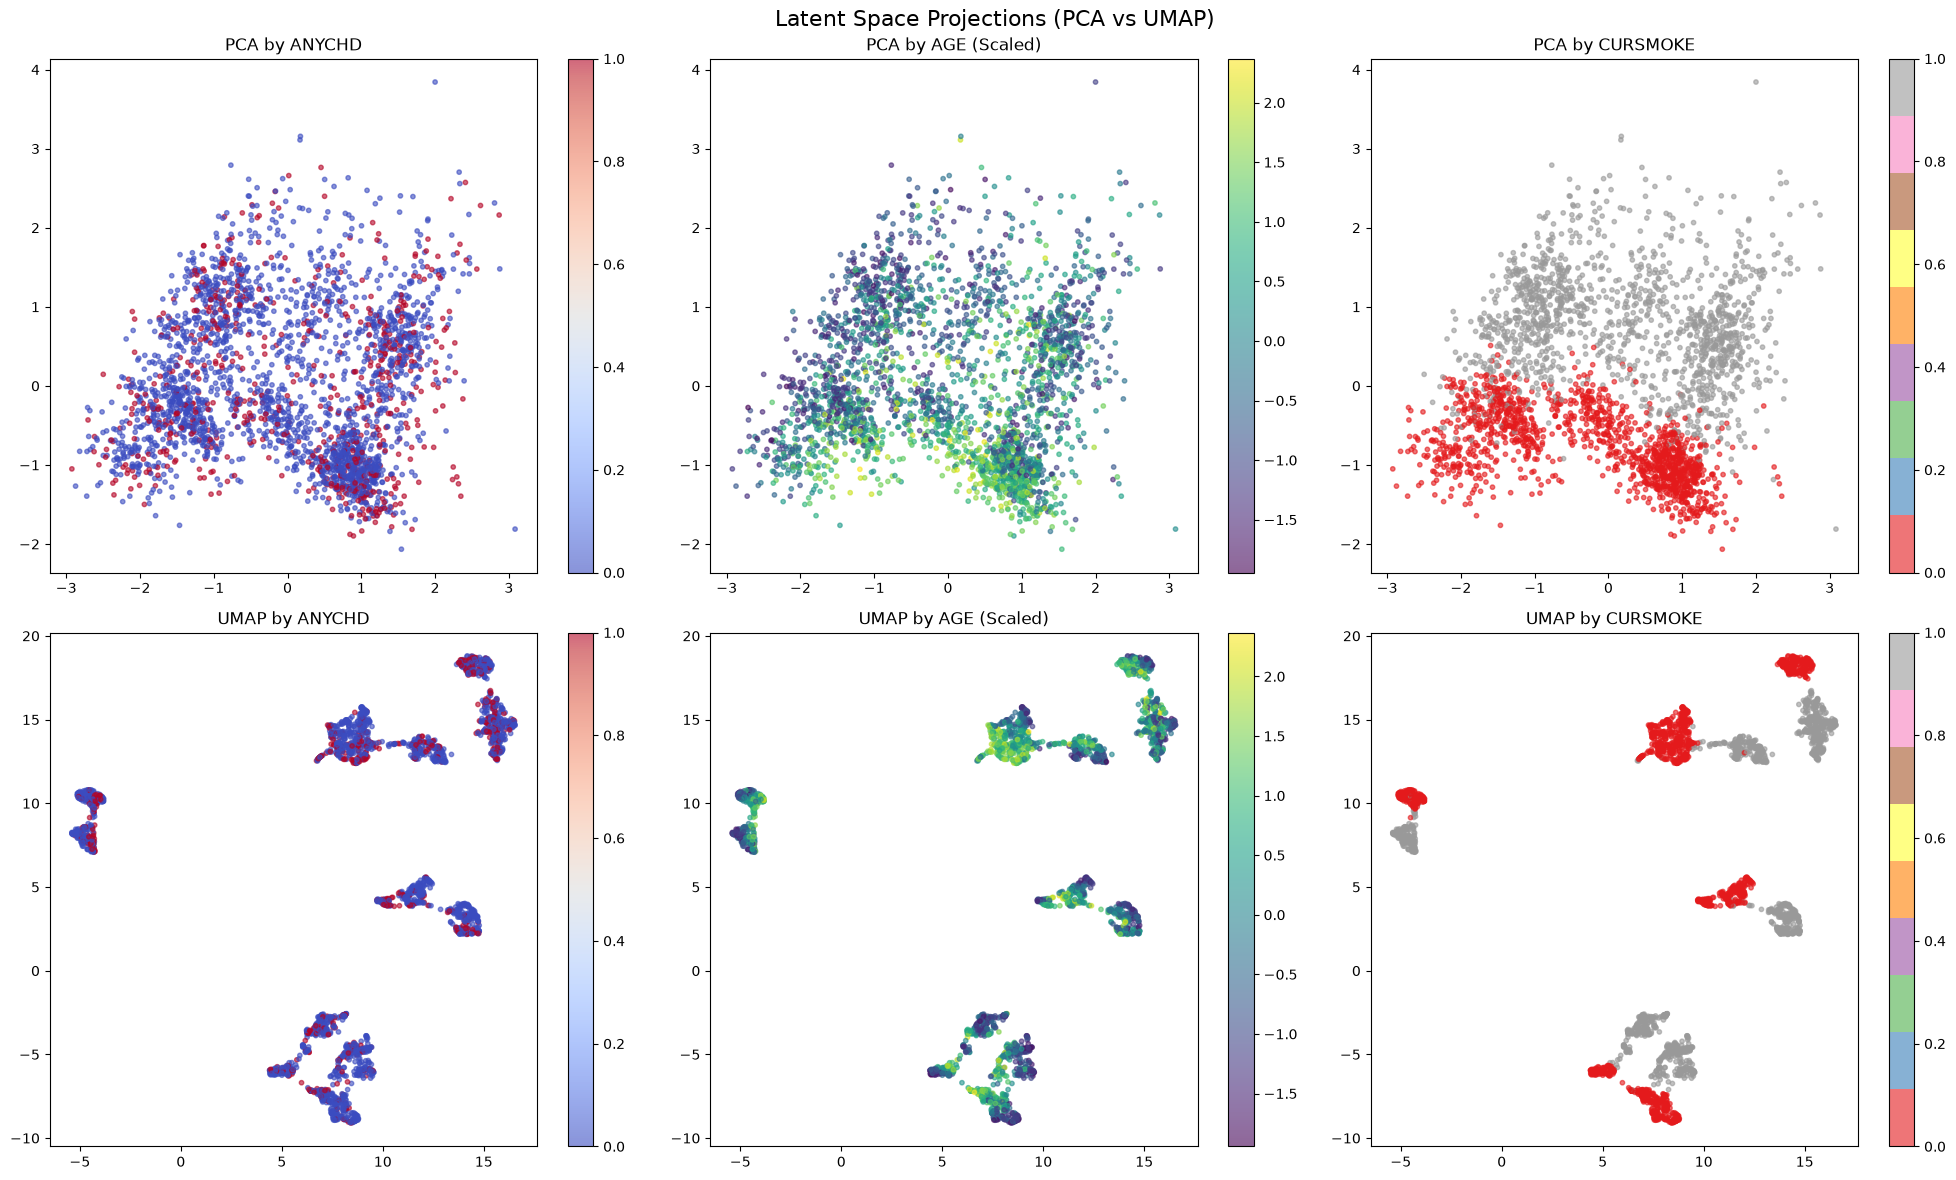

In [27]:
# Extract Latent Representations
best_model.eval()
with torch.no_grad():
    latent_train, _, _, _ = best_model(torch.tensor(X_train, dtype=torch.float32))
    latent_train = latent_train.numpy()

# Extract coloring variables from train_df based on X_train's corresponding rows
# We use y_train_risk (ANYCHD) directly, and we need AGE and CURSMOKE
# feature_cols has 'AGE' and 'CURSMOKE'
age_idx = feature_cols.index('AGE')
smoke_idx = feature_cols.index('CURSMOKE')
y_train_age = X_train[:, age_idx]
y_train_smoke = X_train[:, smoke_idx]

# PCA Projection
pca = PCA(n_components=2, random_state=RANDOM_SEED)
latent_pca = pca.fit_transform(latent_train)

# UMAP Projection
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_SEED)
latent_umap = reducer.fit_transform(latent_train)

fig, axs = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Latent Space Projections (PCA vs UMAP)', fontsize=16)

# PCA
scatter_pca_chd = axs[0, 0].scatter(latent_pca[:, 0], latent_pca[:, 1], c=y_train_risk, cmap='coolwarm', alpha=0.6, s=10)
axs[0, 0].set_title('PCA by ANYCHD')
fig.colorbar(scatter_pca_chd, ax=axs[0, 0])

scatter_pca_age = axs[0, 1].scatter(latent_pca[:, 0], latent_pca[:, 1], c=y_train_age, cmap='viridis', alpha=0.6, s=10)
axs[0, 1].set_title('PCA by AGE (Scaled)')
fig.colorbar(scatter_pca_age, ax=axs[0, 1])

scatter_pca_smoke = axs[0, 2].scatter(latent_pca[:, 0], latent_pca[:, 1], c=y_train_smoke, cmap='Set1', alpha=0.6, s=10)
axs[0, 2].set_title('PCA by CURSMOKE')
fig.colorbar(scatter_pca_smoke, ax=axs[0, 2])

# UMAP
scatter_umap_chd = axs[1, 0].scatter(latent_umap[:, 0], latent_umap[:, 1], c=y_train_risk, cmap='coolwarm', alpha=0.6, s=10)
axs[1, 0].set_title('UMAP by ANYCHD')
fig.colorbar(scatter_umap_chd, ax=axs[1, 0])

scatter_umap_age = axs[1, 1].scatter(latent_umap[:, 0], latent_umap[:, 1], c=y_train_age, cmap='viridis', alpha=0.6, s=10)
axs[1, 1].set_title('UMAP by AGE (Scaled)')
fig.colorbar(scatter_umap_age, ax=axs[1, 1])

scatter_umap_smoke = axs[1, 2].scatter(latent_umap[:, 0], latent_umap[:, 1], c=y_train_smoke, cmap='Set1', alpha=0.6, s=10)
axs[1, 2].set_title('UMAP by CURSMOKE')
fig.colorbar(scatter_umap_smoke, ax=axs[1, 2])

plt.tight_layout()
plt.savefig('../results/latent_space_projection.png')
plt.show()

